<a href="https://colab.research.google.com/github/tettehdaniel/python-labs/blob/main/Notebooks/Notebook08_DataVis2_SV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 08 — Data Visualization Two

**Main Objective**

1. Different Aesthetics
2. Types of Geometries

## Setup

Please run the setup code below

In [1]:
! wget -q -nc https://raw.githubusercontent.com/taylor-arnold/fds-py/refs/heads/main/funs.py

from funs import *

In [2]:
import numpy as np
import polars as pl

from plotnine import *
from polars import col as c
theme_set(theme_minimal())

path = "https://raw.githubusercontent.com/ajcollins16/DSST289_Fall2026_AJC/refs/heads/main/"

In [3]:
dat = pl.read_csv(path + "Data/metro.csv").filter(c.quad != "0")

## Aesthetics and Geometries

Today we will further explore aesthetic options to better destinguish our data visually as well as learn about several other forms of data visualization through different geometries. We will be using the metro dataset which we saw a few weeks ago.

### Questions

1. Let's start with a scatterplot. Start by plotting the household median income on the x-axis and the density on the y-axis.

In [4]:
dat

name,geoid,quad,lon,lat,pop,density,age_median,hh_income_median,percent_own,rent_1br_median,rent_perc_income,division
str,i64,str,f64,f64,f64,f64,f64,i64,f64,i64,f64,str
"""New York""",35620,"""NE""",-74.101056,40.76877,20.011812,1051.306467,42.9,86445,55.3,1430,31.0,"""Middle Atlantic"""
"""Los Angeles""",31080,"""W""",-118.148722,34.219406,13.202558,1040.647281,41.6,81652,51.3,1468,33.6,"""Pacific"""
"""Chicago""",16980,"""NC""",-87.95882,41.700605,9.607711,508.629406,41.9,78790,68.9,1060,29.0,"""East North Central"""
"""Dallas""",19100,"""S""",-96.970508,32.84948,7.54334,323.181404,41.3,76916,64.1,1106,29.1,"""West South Central"""
"""Houston""",26420,"""S""",-95.401574,29.787083,7.048954,316.543514,41.0,72551,65.1,997,30.0,"""West South Central"""
…,…,…,…,…,…,…,…,…,…,…,…,…
"""Zapata""",49820,"""S""",-99.168533,27.000573,0.013945,5.081383,41.4,34406,77.1,321,34.6,"""West South Central"""
"""Ketchikan""",28540,"""O""",-130.927217,55.582484,0.013939,1.046556,44.6,77820,67.5,946,31.2,"""Pacific"""
"""Craig""",18780,"""W""",-108.207523,40.618749,0.01324,1.077471,44.5,58583,72.8,485,29.0,"""Mountain"""


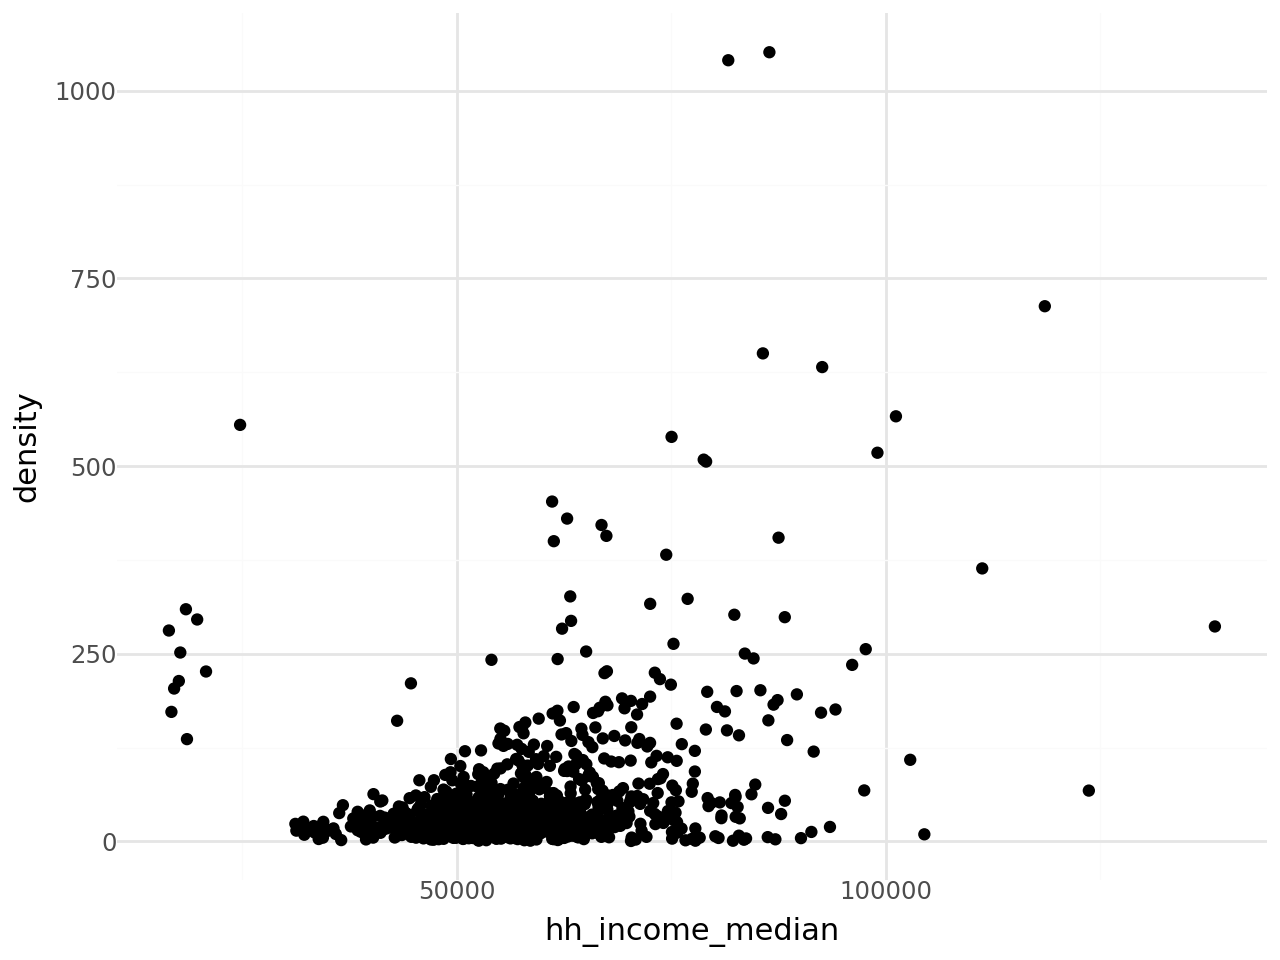

In [5]:
(
    dat
    .pipe(ggplot, aes(x="hh_income_median", y="density"))
    +geom_point()
)

1. When you look at this output, what are two issues that come to mind when trying to interpret this?

**Answer (Q1):** Color, Cluster

2. Let's modify the plot to only include those where the population is greater than 2 million people (remember, population is recorded in millions in the data).

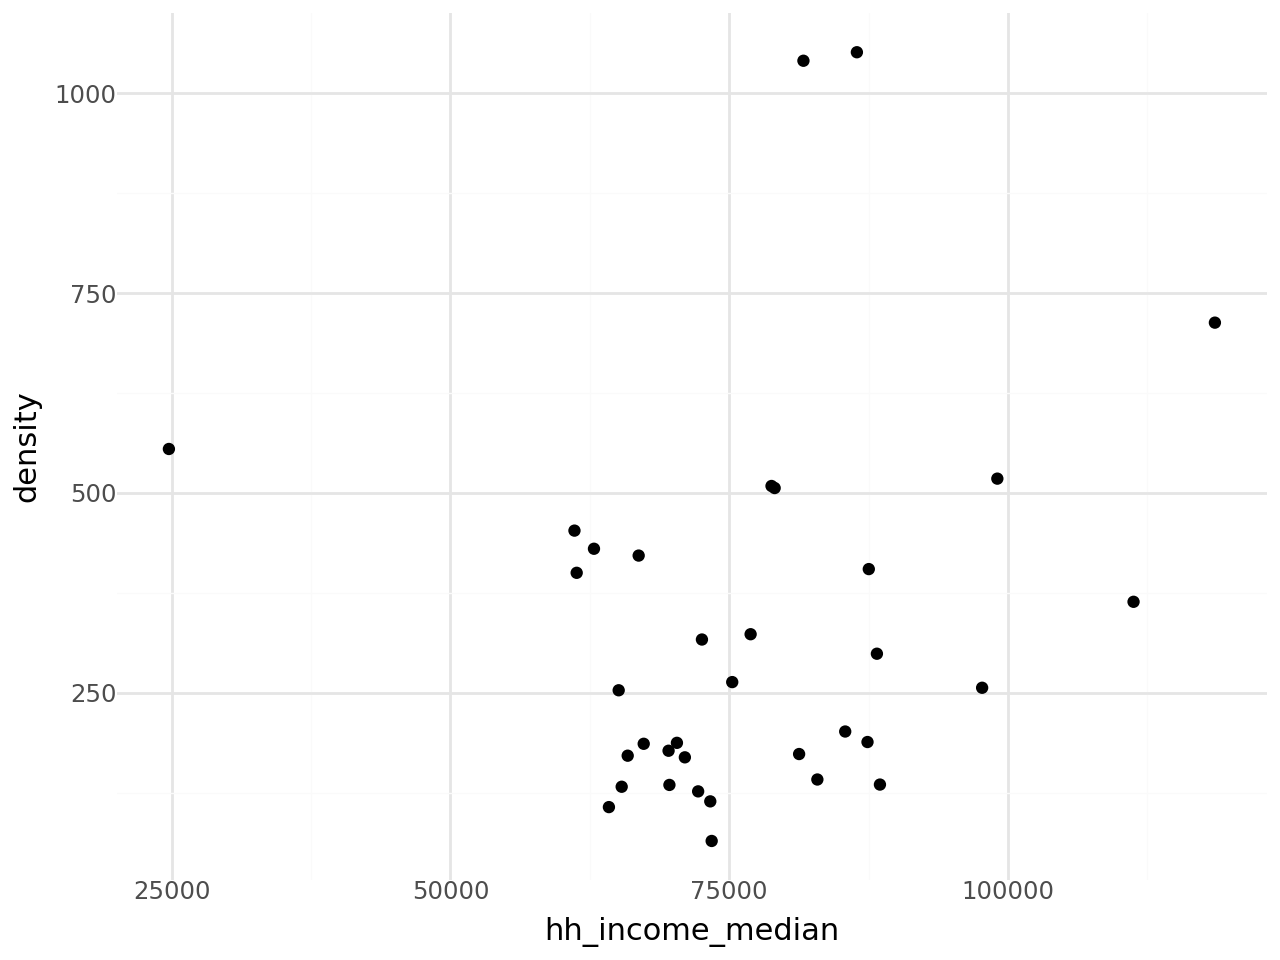

In [6]:
(
    dat
    .filter(c.pop > 2)
    .pipe(ggplot, aes(x="hh_income_median", y="density"))
    +geom_point()
)

3. Recreate the previous plot, but this time color the points by division. Notice that `color` goes inside `aes()` when mapping to a variable.

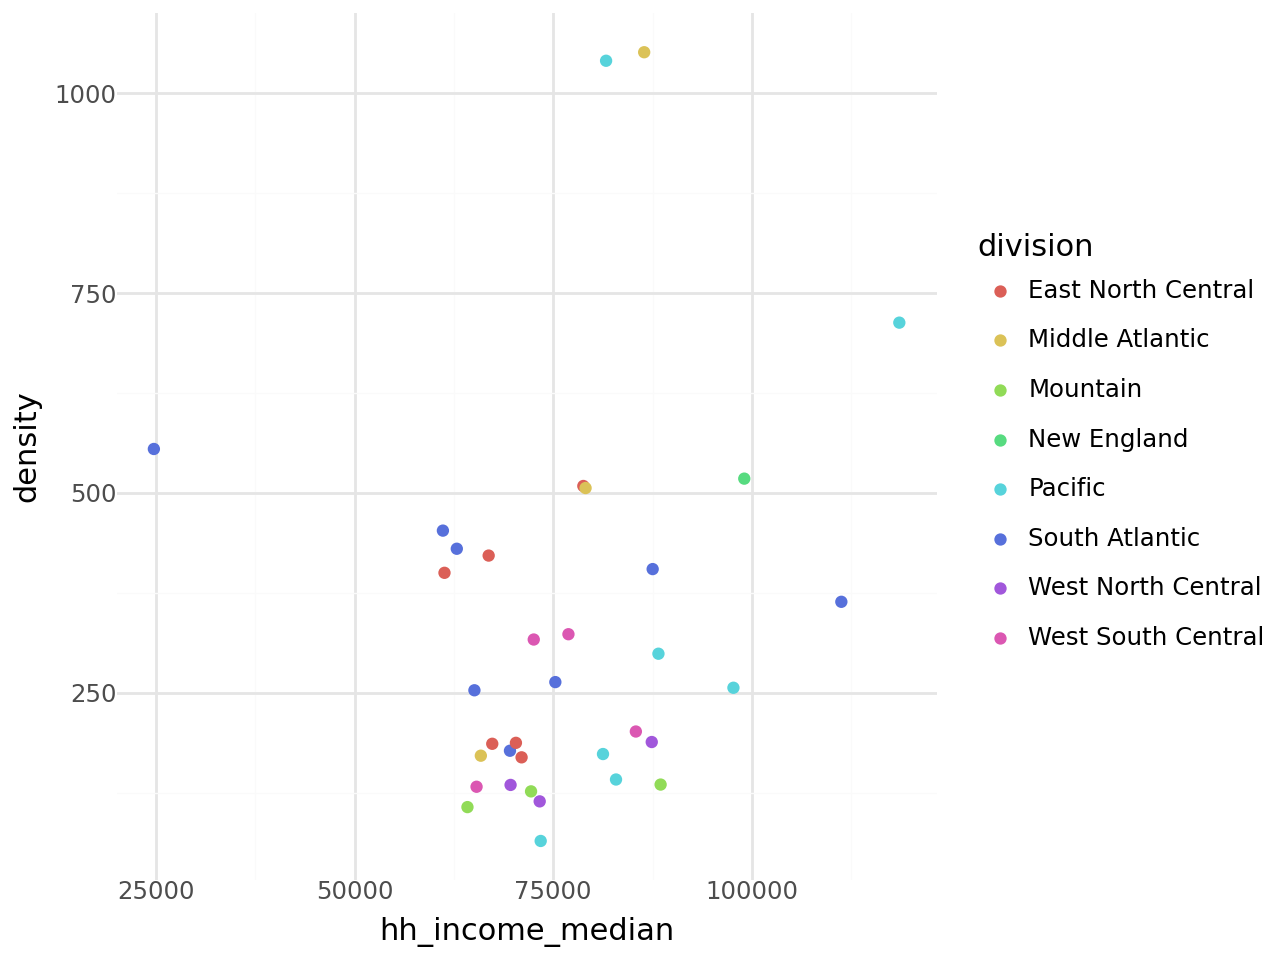

In [7]:
(
    dat
    .filter(c.pop > 2)
    .pipe(ggplot, aes(x="hh_income_median", y="density"))
    +geom_point(aes(color="division"))
)

4. Use a [Color Wheel](https://htmlcolorcodes.com/color-wheel/) to select a fun color. In the code below, update the previous plot to use this fixed color in place of the color based on our division variable. Notice that when using a fixed color (not mapped to data), `color` goes outside of `aes()`.

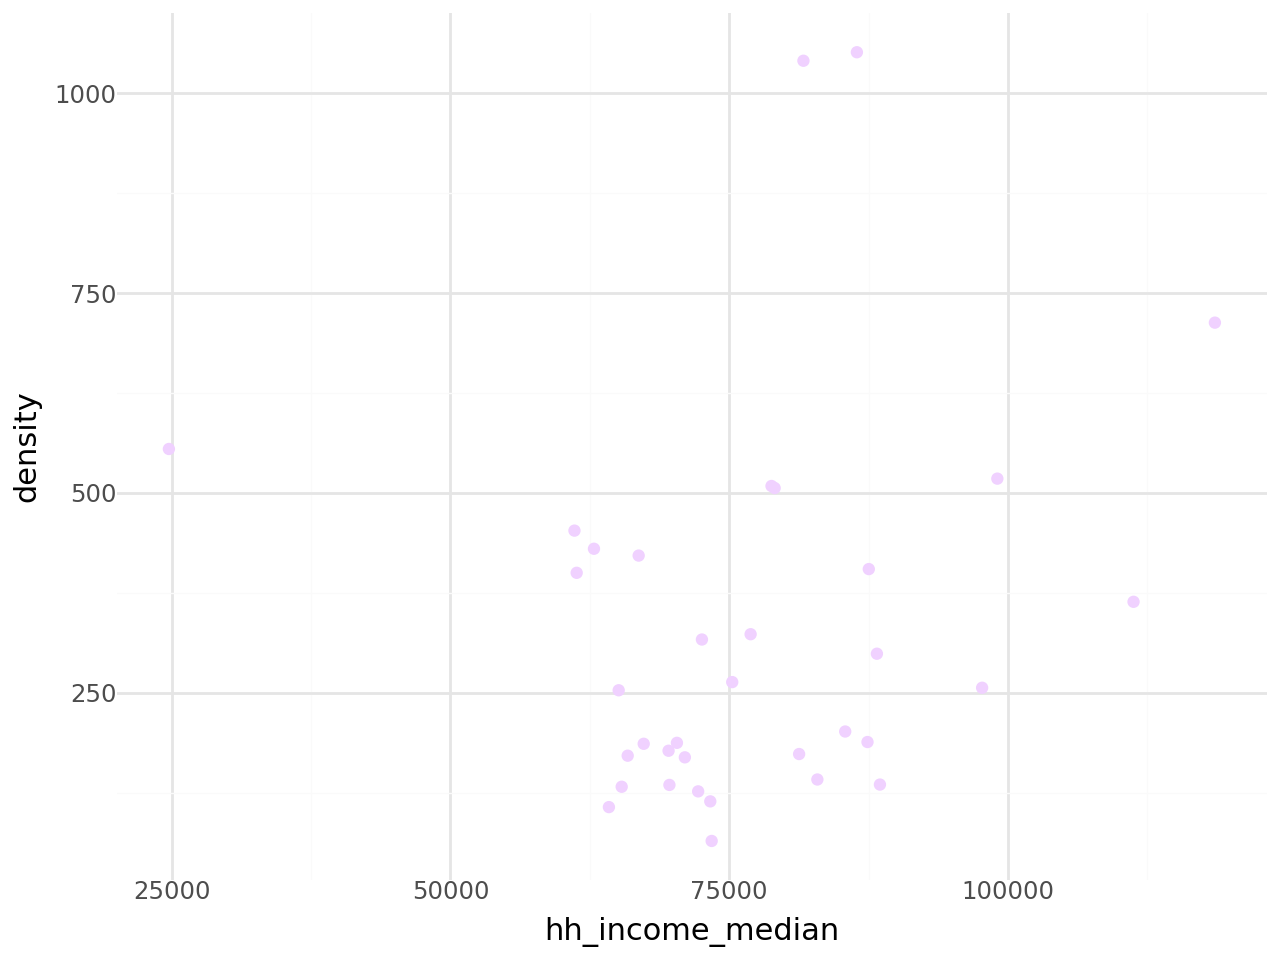

In [9]:
(
    dat
    .filter(c.pop > 2)
    .pipe(ggplot, aes(x="hh_income_median", y="density"))
    +geom_point(color="#F0D1FF")
)

5. Now, instead of points, use text labels to display the item names. Replace `geom_point()` with `geom_text()` and map the `label` aesthetic to the `name` column. Keep the fixed color you choose.

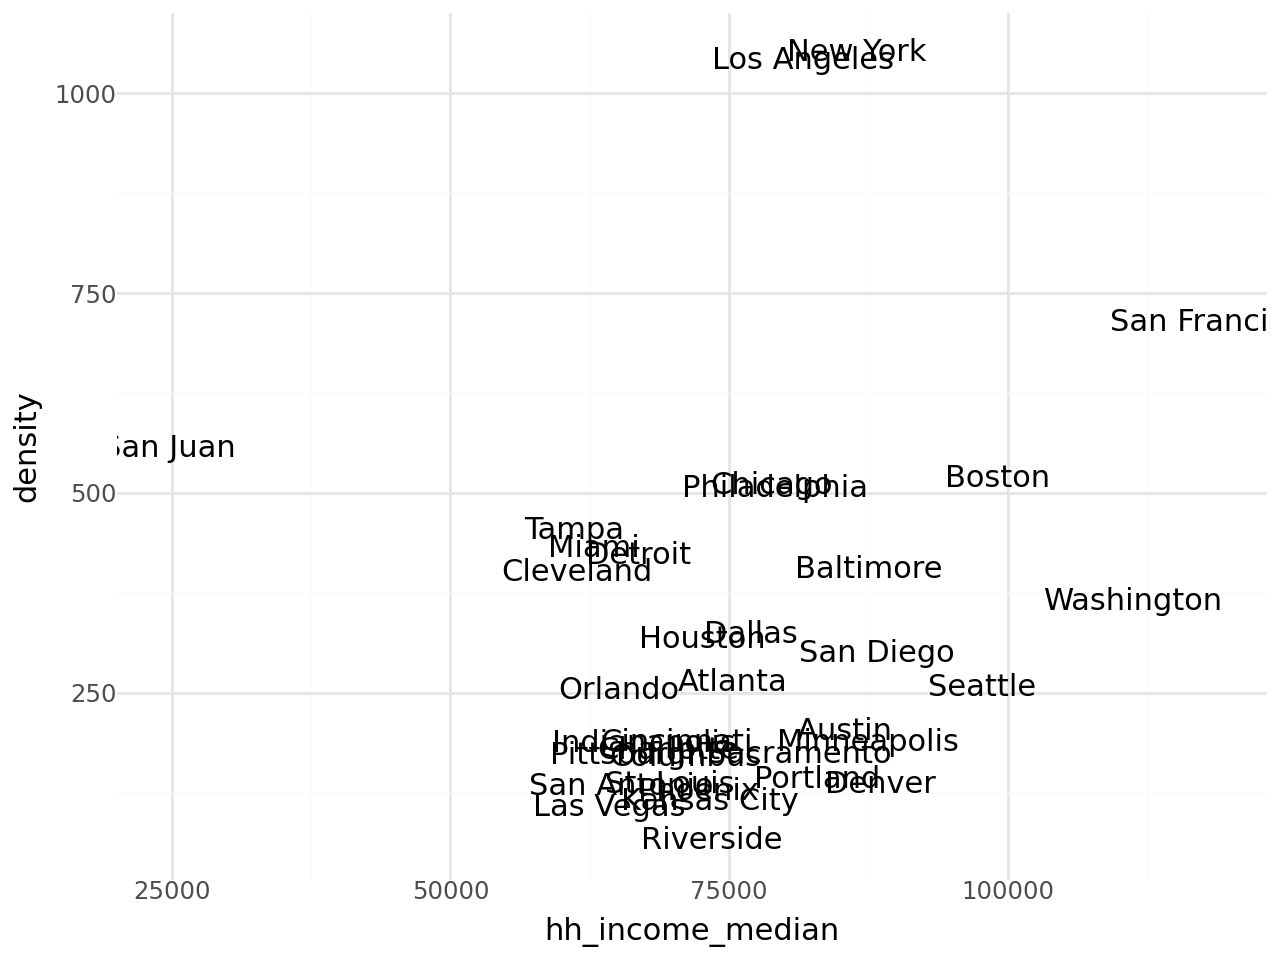

In [10]:
(
    dat
    .filter(c.pop > 2)
    .pipe(ggplot, aes(x="hh_income_median", y="density"))
    +geom_text(aes(label="name"))
)

6. Next, add both points and text labels to the plot. Use `nudge_y` (note that this follows your axes own scale so the number needs to match that scale) to shift the text up slightly so it doesn't overlap with the points and set the size a bit smaller to make it all easier to read. Keep the fixed color, keeping in mind where it needs to go in the code.

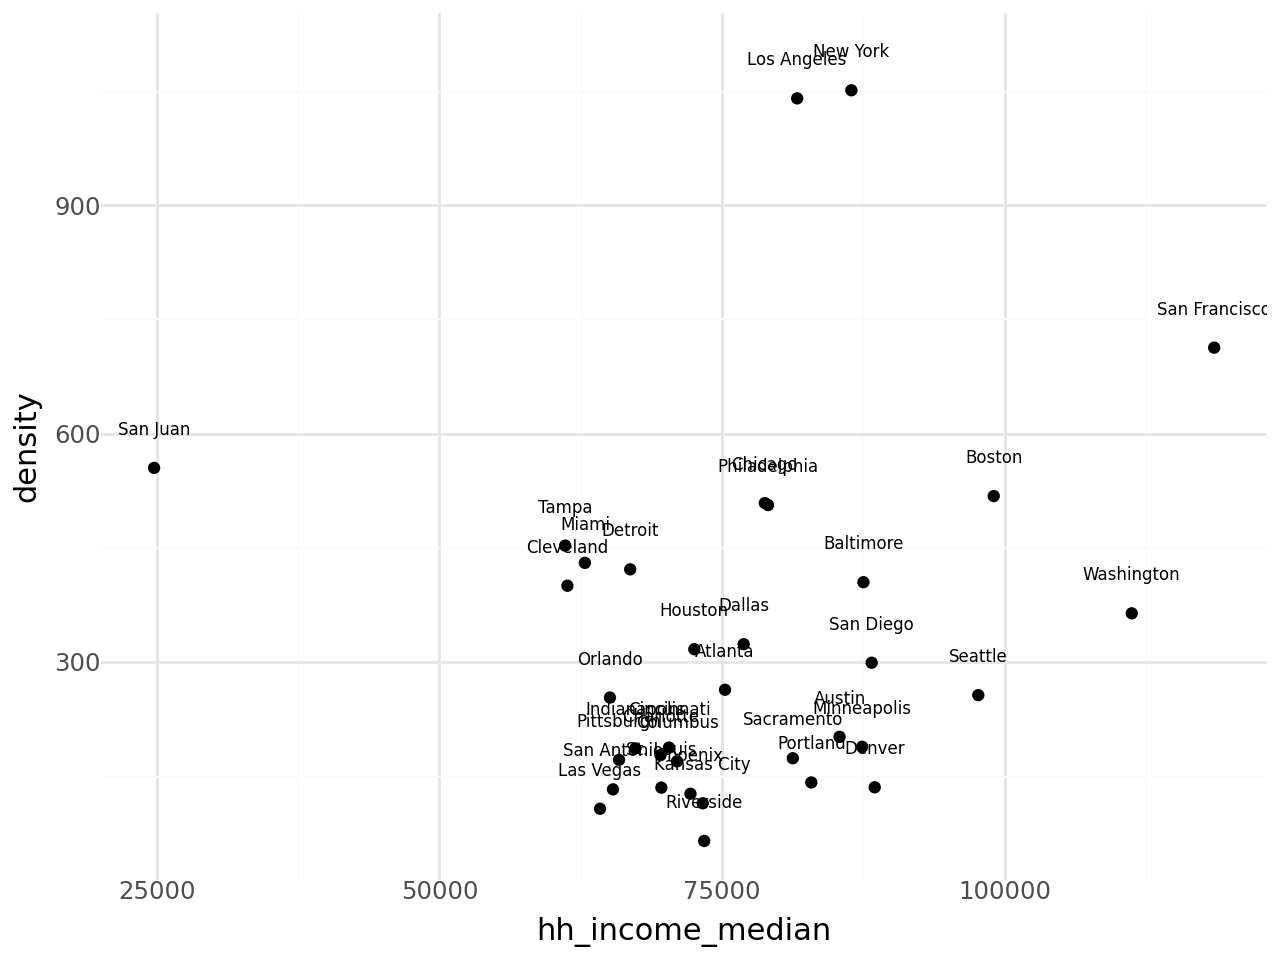

In [40]:
(
    dat
    .filter(c.pop > 2)
    .pipe(ggplot, aes(x="hh_income_median", y="density"))
    +geom_point()
    + geom_text(aes(label="name"), size=6, nudge_y=50)
)

7. Now, summarize the data by counting the number of metro regions (from the whole dataset, not just those with a population greater than 2 million) within each division. Plot this using a bar/column plot with division on the x-axis and count on the y-axis.

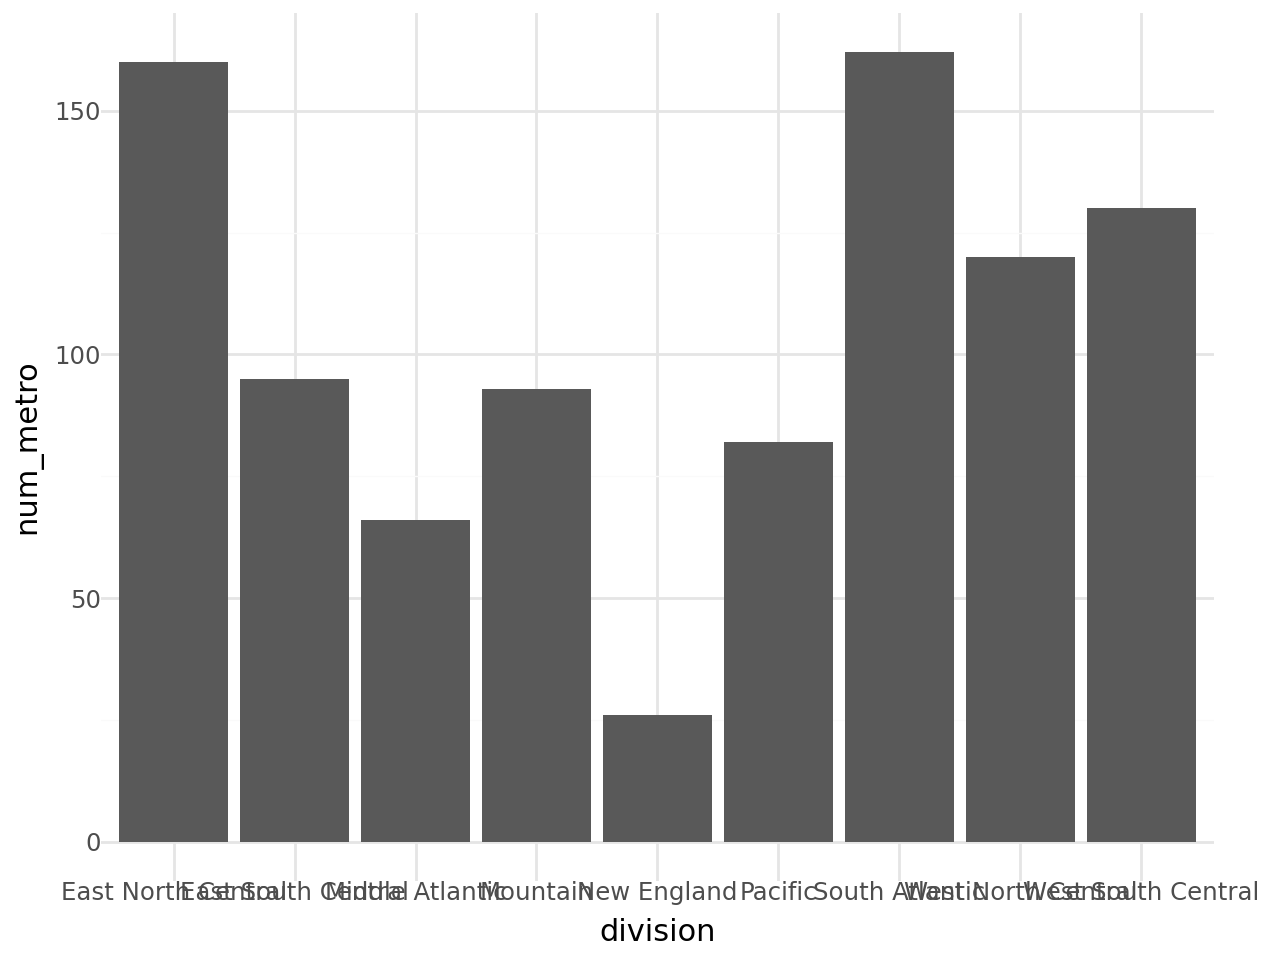

In [17]:
(
    dat
    .group_by(c.division)
    .agg(
        num_metro = pl.len()
    )
    .pipe(ggplot, aes(x="division", y="num_metro"))
    +geom_col()

)

8. Modify your previous plot by flipping the axes and ordering the divisions by the counts.

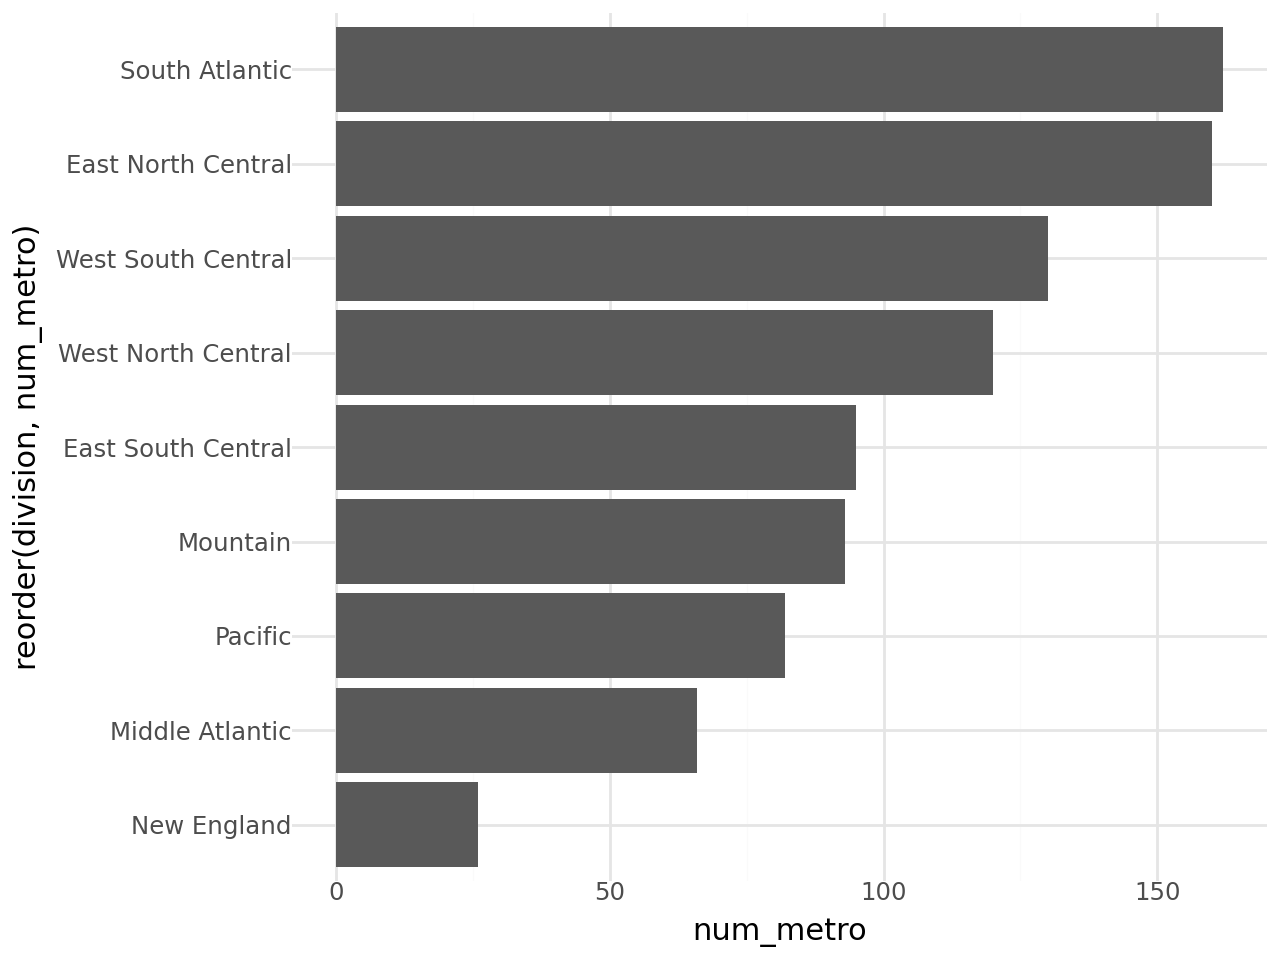

In [35]:
(
    dat
    .group_by(c.division)
    .agg(
        num_metro = pl.len()
    )
    .pipe(ggplot, aes(x="reorder(division, num_metro)", y="num_metro"))
    +geom_col()
    +coord_flip()
)

9. Finally, modify the plot by making the bars *filled* with the custom color you selected above.

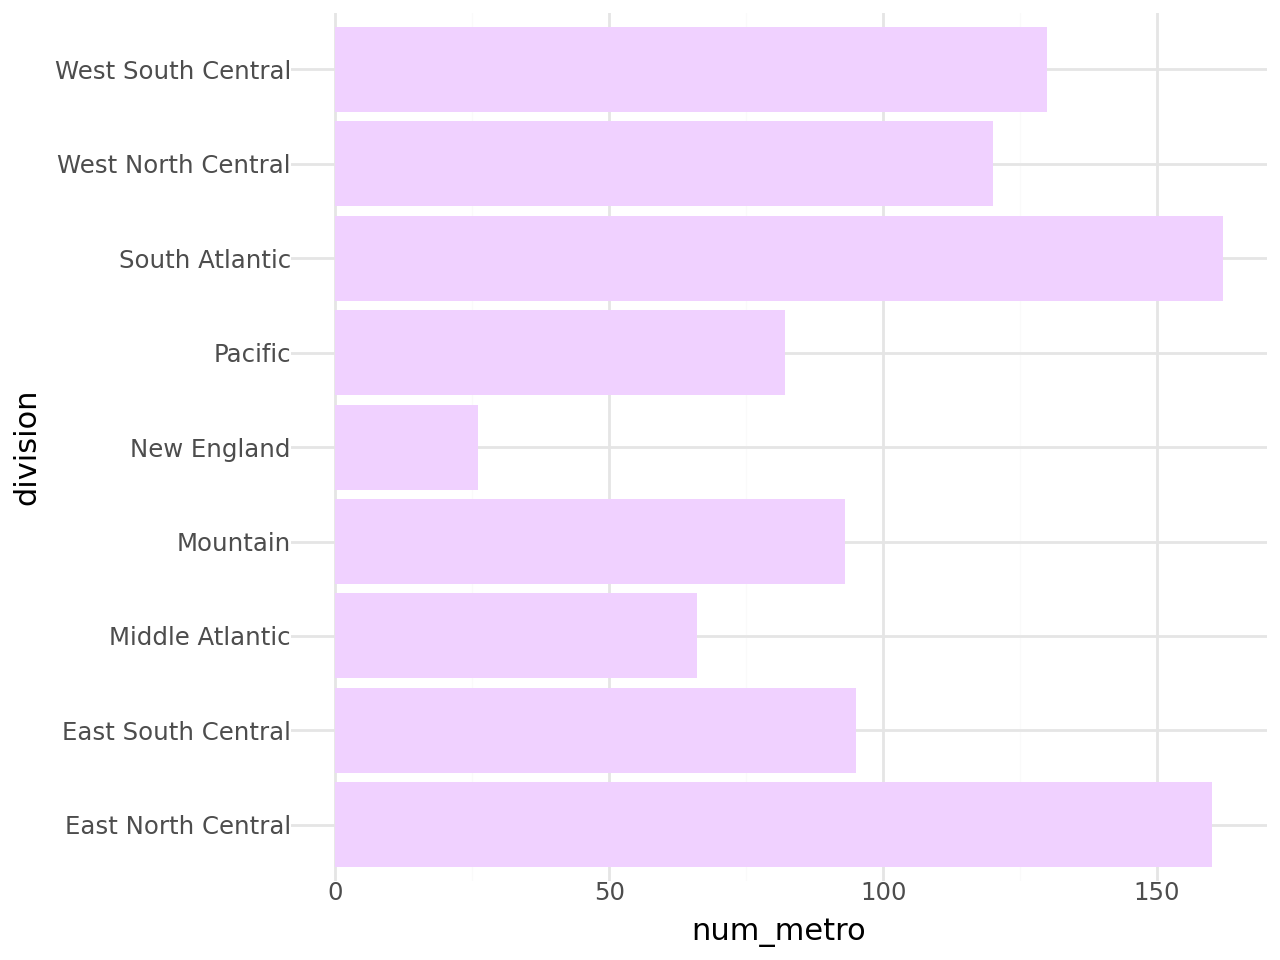

In [30]:
(
    dat
    .group_by(c.division)
    .agg(
        num_metro = pl.len()
    )
    .pipe(ggplot, aes(x="division", y="num_metro"))
    +geom_col(fill="#F0D1FF")
    +coord_flip()
)

10. What is the difference between *fill* and *color* within something like a bar/column plot? If you want to feel free to test it out below.

**Answer (Q10):** "Color" only colors the egde of the bar/column, while "fill" fills the entre bar.